# Video Processing & Analytics walkthrough — one video, S1 → S9

CSE4076 Image and Video Analytics · *Real-Time Illicit Activity Detection System*

This notebook follows **one UCF-Crime video** (`Robbery137_x264`, from the fixed sample set) through every
pre-training stage of the VPA pipeline. It calls the **same functions** as `src/preprocessing/extract_clips.py`,
and shows each stage's input next to its output. No model is trained anywhere: Zero-DCE++ and YOLO are the existing
weights, every other model is classical or pretrained (RAFT-small, FastDVDnet).

| Stage | What it does |
|---|---|
| S1 | video profiling & quality statistics |
| S2 | timestamp-based resampling to exactly 12 FPS |
| S3 | shot cuts, frozen/black frames, letterbox bars, timestamp overlay |
| S4 | one brightness measure → Zero-DCE++ → temporal denoise → deflicker |
| S5 | camera-motion compensation — **skipped** (only 2/300 videos move; see below) |
| S6 | background subtraction, optical flow, MHI, motion-energy signal |
| S7 | person detection, ByteTrack, interaction signals, actor-centred crop |
| S8 | activity score, action proposals, clip selection, quality gate, dedup |
| S9 | uint8 clips + JSON sidecars + dataset report |

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from preprocessing.vpa import (common, profile, decode, clean, enhance, motion, actors, temporal, package, viz, legacy)
from preprocessing.vpa.common import load_config, find_video, load_temporal_gt, CACHE_DIR
cfg = load_config()
STEM = 'Robbery137_x264'
video = find_video(STEM)
gt_sec = [(a / 30.0, b / 30.0) for a, b in load_temporal_gt().get(STEM, [])]
models = {}          # lazily loaded heavy models (Zero-DCE++, FastDVDnet, YOLO, RAFT, pyiqa)
print(STEM, video['label'], 'ground-truth event (s):', gt_sec)

def show(imgs, titles=None, cols=None, w=4.2, h=3.2, suptitle=None):
    imgs = imgs if isinstance(imgs, (list, tuple)) else [imgs]
    cols = cols or len(imgs)
    rows = int(np.ceil(len(imgs) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(w * cols, h * rows), squeeze=False)
    for ax in axs.ravel():
        ax.axis('off')
    for i, im in enumerate(imgs):
        ax = axs.ravel()[i]
        ax.imshow(cv2.cvtColor(viz.to_bgr(im), cv2.COLOR_BGR2RGB))
        if titles:
            ax.set_title(titles[i], fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    fig.tight_layout()
    plt.show()

Robbery137_x264 Robbery ground-truth event (s): [(4.5, 65.0)]


## S1 — video profiling & quality assessment
One decode pass collects stream metadata, I/P/B shares, brightness, sharpness (Laplacian variance), noise, blockiness, camera-motion and overlay scores. The dataset-level numbers set the thresholds used later.

,value
field,
codec,h264
width,320
height,240
pix_fmt,yuv420p
fps_avg,30.0
fps_measured,30.0
vfr,False
bit_rate,1939976
duration_s,73.1


derived thresholds: {'dark_threshold': 50.0, 'dark_threshold_otsu': 76.0, 'blur_lap_var_p5': 268.53}
dataset: {'n_videos': 300, 'fps': [30.0], 'resolutions': ['320x240'], 'with_letterbox_bars': 206, 'with_overlay': 218, 'with_cut_candidates': 72, 'moving_camera_videos': 2}


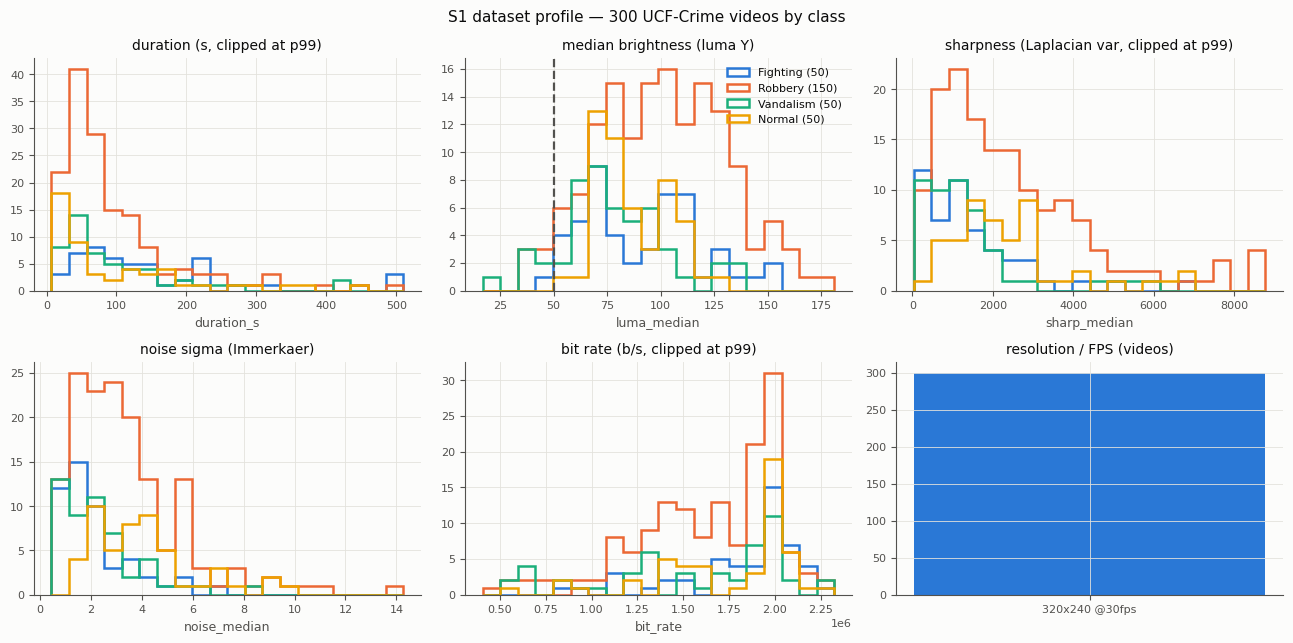

In [2]:
prof = profile.profile_video(video['path'])
meta = {k: prof[k] for k in ['codec', 'width', 'height', 'pix_fmt', 'fps_avg', 'fps_measured', 'vfr', 'bit_rate', 'duration_s', 'n_frames', 'ipb_frac',
                              'luma_median', 'sharp_median', 'noise_median', 'block_median', 'frozen_frac', 'cut_candidates', 'cam_moving_frac',
                              'has_bars', 'bars', 'overlay_components']}
display(pd.DataFrame(meta.items(), columns=['field', 'value']).set_index('field'))
profiles = profile.profile_dataset()                      # cached: all 300 videos
thr = profile.derive_thresholds(profiles)
summary = profile.dataset_summary(profiles)
print('derived thresholds:', {k: (round(v, 2) if isinstance(v, float) else v) for k, v in thr.items() if k in ('dark_threshold', 'dark_threshold_otsu', 'blur_lap_var_p5')})
print('dataset:', {k: summary[k] for k in ('n_videos', 'fps', 'resolutions', 'with_letterbox_bars', 'with_overlay', 'with_cut_candidates', 'moving_camera_videos')})
profile.plot_dataset_histograms(profiles, thr); plt.show()

## S2 — decode and resample to exactly 12 FPS
OLD: `step = round(src_fps/12)` → 30 FPS source gives 15 FPS. NEW: pick, for every `t = k/12 s`, the source frame with the nearest presentation timestamp.

source 30.00 FPS | OLD effective 15.0 FPS | NEW effective 12.00 FPS | max timing error 16.7 ms


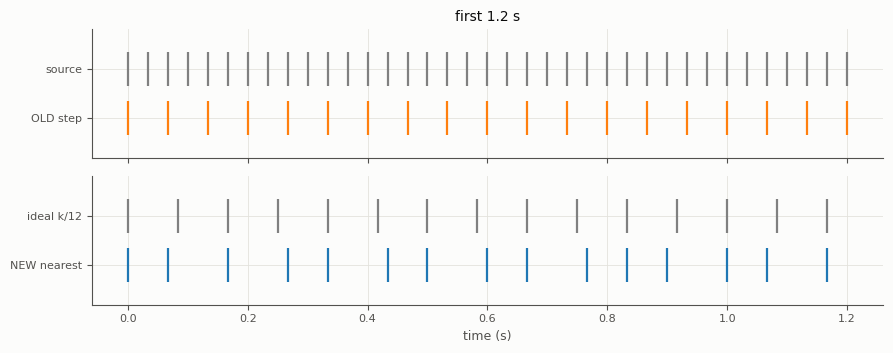

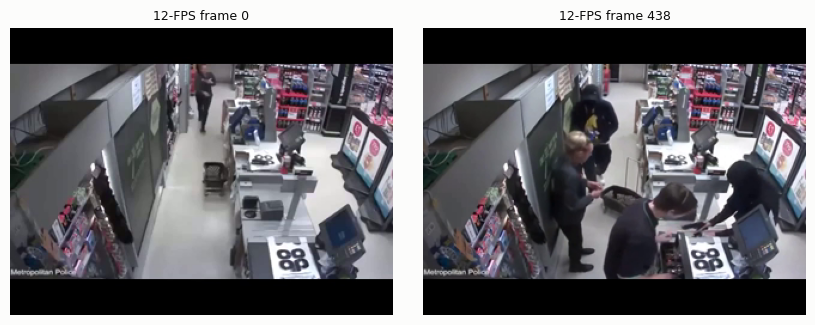

In [3]:
dec = decode.decode_12fps(video['path'], max_seconds=cfg['general']['sample_max_seconds'])
frames = dec['frames']
old_idx, old_t, old_fps = decode.legacy_indices(dec['nominal_fps'], dec['n_src_frames'])
new_fps = (len(frames) - 1) / (dec['t_target'][-1] - dec['t_target'][0])
print(f"source {dec['src_fps']:.2f} FPS | OLD effective {old_fps:.1f} FPS | NEW effective {new_fps:.2f} FPS | max timing error {dec['max_timing_error_s']*1000:.1f} ms")
fig, axs = plt.subplots(2, 1, figsize=(9, 3.6), sharex=True)
src_t = np.arange(37) / dec['src_fps']
axs[0].eventplot([src_t, old_t[old_t <= 1.2]], lineoffsets=[1, 0], linelengths=.7, colors=['gray', 'tab:orange'])
axs[0].set_yticks([1, 0]); axs[0].set_yticklabels(['source', 'OLD step']); axs[0].set_title('first 1.2 s')
axs[1].eventplot([np.arange(15) / 12, dec['t_src'][dec['t_src'] <= 1.2]], lineoffsets=[1, 0], linelengths=.7, colors=['gray', 'tab:blue'])
axs[1].set_yticks([1, 0]); axs[1].set_yticklabels(['ideal k/12', 'NEW nearest']); axs[1].set_xlabel('time (s)')
plt.tight_layout(); plt.show()
show([frames[0], frames[len(frames)//2]], ['12-FPS frame 0', f'12-FPS frame {len(frames)//2}'])

## S3 — structural cleaning
Letterbox bars → overlay (timestamp / logo) masking and inpainting → shot-cut detection → frozen/black frames.

letterbox bars: {'top': 32, 'bottom': 32, 'left': 0, 'right': 0} -> content box (0, 32, 320, 208)


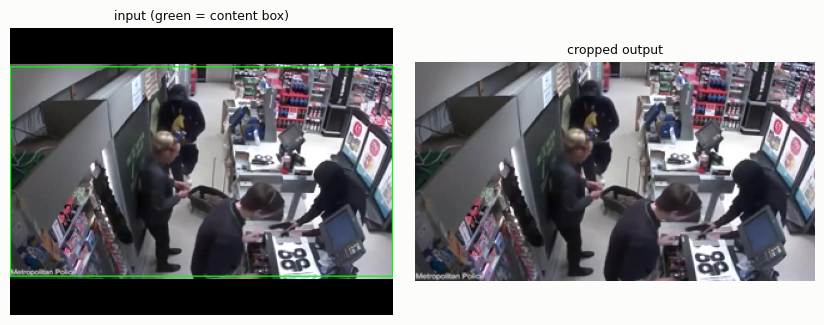

overlay components: 2 area fraction: 0.0102


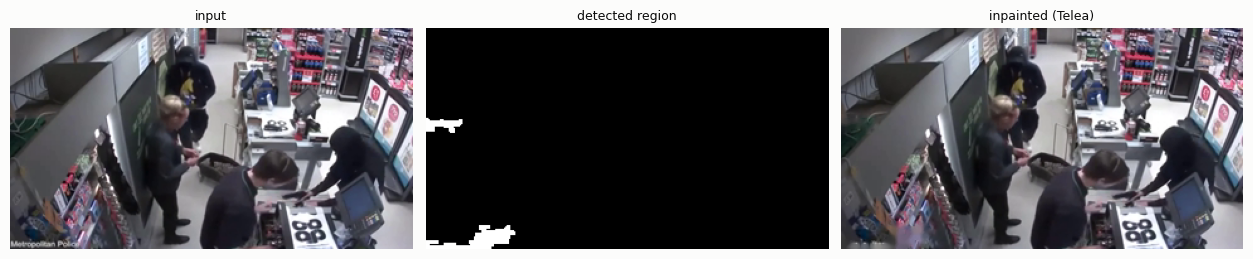

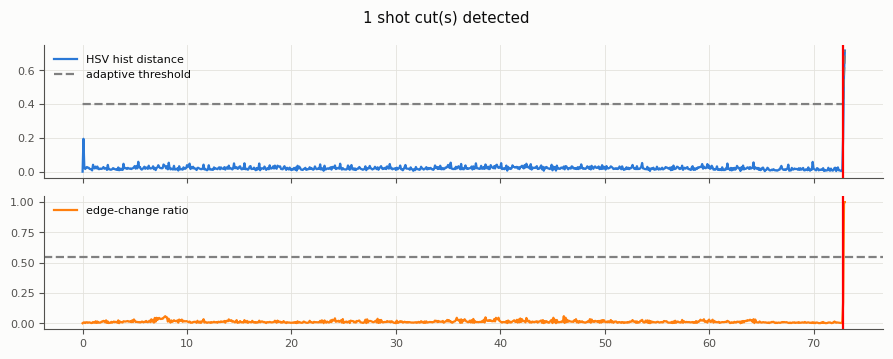

frozen frames: 0 | black frames: 1


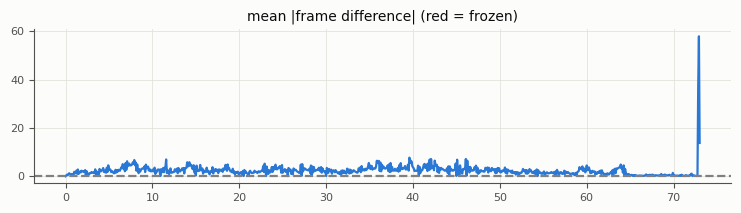

In [4]:
lb = clean.detect_letterbox(frames, cfg)
frames_c = clean.apply_crop(frames, lb['box']) if lb['has_bars'] else frames
print('letterbox bars:', lb['bars'], '-> content box', lb['box'])
mid = len(frames) // 2
marked = frames[mid].copy(); x0, y0, x1, y1 = lb['box']; cv2.rectangle(marked, (x0, y0), (x1 - 1, y1 - 1), (0, 255, 0), 1)
show([marked, frames_c[mid]], ['input (green = content box)', 'cropped output'])

ov = clean.detect_overlay(frames_c, cfg)
frames_o, masks = clean.remove_overlay(frames_c, ov['region'], cfg, return_masks=True)
print('overlay components:', ov['n_components'], 'area fraction:', round(ov['area_frac'], 4))
show([frames_c[mid], cv2.cvtColor(ov['region'] * 255, cv2.COLOR_GRAY2BGR), frames_o[mid]], ['input', 'detected region', 'inpainted (Telea)'])

sd = clean.detect_shot_cuts(frames_o, cfg)
shot_ids = clean.shot_ids_from_cuts(len(frames_o), sd['cuts'])
fig, axs = plt.subplots(2, 1, figsize=(9, 3.6), sharex=True)
t = np.arange(len(frames_o)) / 12
axs[0].plot(t, sd['hist_dist'], label='HSV hist distance'); axs[0].plot(t, sd['thr'], '--', color='gray', label='adaptive threshold'); axs[0].legend()
axs[1].plot(t, sd['ecr'], color='tab:orange', label='edge-change ratio'); axs[1].axhline(cfg['clean']['shot_cut']['ecr_min'], ls='--', color='gray'); axs[1].legend()
for c in sd['cuts']:
    axs[0].axvline(c / 12, color='red'); axs[1].axvline(c / 12, color='red')
plt.suptitle(f"{len(sd['cuts'])} shot cut(s) detected"); plt.tight_layout(); plt.show()

fz = clean.detect_frozen_black(frames_o, cfg)
print('frozen frames:', fz['n_frozen'], '| black frames:', fz['n_black'])
fig, ax = plt.subplots(figsize=(9, 2)); ax.plot(t, fz['diff']); ax.axhline(cfg['clean']['frozen']['diff_thr'], ls='--', color='gray')
ax.fill_between(t, 0, fz['diff'].max(), where=fz['frozen'], color='red', alpha=.3); ax.set_title('mean |frame difference| (red = frozen)'); plt.show()
cl = dict(frames=frames_o, shot_ids=shot_ids, cuts=sd['cuts'], frozen=fz, overlay=ov, crop_box=lb['box'])

## S4 — photometric enhancement
One brightness measure (mean luma Y) and one threshold decide which frames are dark. This video is **not dark**, so S4 leaves it untouched; to show what the chain does, the demo darkens a 3-second window (clearly **simulated**) and runs raw / CLAHE / Zero-DCE++ / Zero-DCE++ + denoise + deflicker.

dark threshold 50 | dark frames: 0.1%


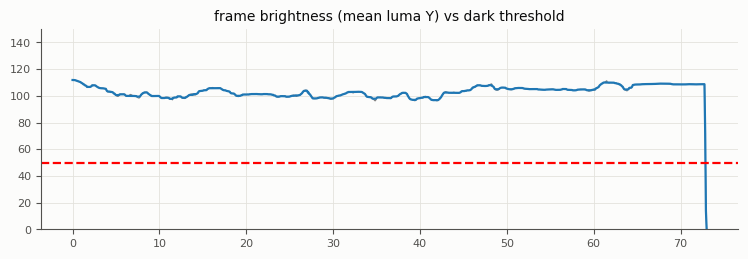

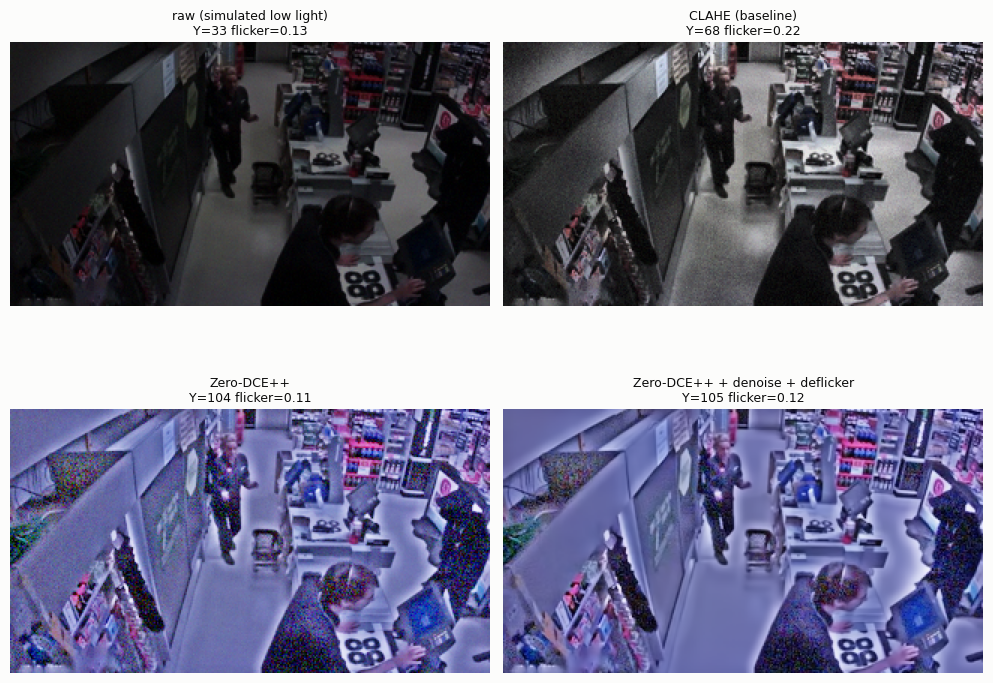

,mean_luma,flicker_index,noise_sigma,niqe,brisque,yolo_persons_per_frame
raw (simulated low light),32.575,0.134,2.582,5.427,10.522,3.083
CLAHE (baseline),68.174,0.215,6.259,6.497,22.400,2.917
Zero-DCE++,104.488,0.107,8.646,6.202,32.960,3.167
Zero-DCE++ + denoise + deflicker,104.604,0.117,5.259,5.956,27.583,3.083


frames changed by S4: 1


In [5]:
luma = enhance.luma_series(frames_o)
dark, sm = enhance.dark_decision(luma, cfg)
print(f"dark threshold {cfg['enhance']['dark_threshold']} | dark frames: {dark.mean():.1%}")
fig, ax = plt.subplots(figsize=(9, 2.6)); ax.plot(t, luma, color='gray', lw=.8); ax.plot(t, sm, color='tab:blue')
ax.axhline(cfg['enhance']['dark_threshold'], ls='--', color='red'); ax.set_ylim(0, 150); ax.set_title('frame brightness (mean luma Y) vs dark threshold'); plt.show()

win = frames_o[100:136]
low = enhance.simulate_low_light(win)
det = actors.get_detector(models)
variants = {'raw (simulated low light)': low, 'CLAHE (baseline)': enhance.clahe_frames(low)}
plain = enhance.process_run(low, cfg, models, 'cuda', alpha_ema=0.0, denoise=False, deflicker=False)
full = enhance.process_run(low, cfg, models, 'cuda')
variants['Zero-DCE++'] = plain['frames']; variants['Zero-DCE++ + denoise + deflicker'] = full['frames']
mets = {k: enhance.variant_metrics(v, models, 'cuda', det) for k, v in variants.items()}
show([v[18] for v in variants.values()], [f"{k}\nY={mets[k]['mean_luma']:.0f} flicker={mets[k]['flicker_index']:.2f}" for k in variants], cols=2, w=5, h=4)
display(pd.DataFrame(mets).T.round(3))
en = enhance.enhance_video(frames_o, shot_ids, cfg, models)          # the real S4 call on the whole video (no-op: bright)
frames_e = en['frames']
print('frames changed by S4:', int(en['enhanced'].sum()))

## S5 — camera-motion compensation (skipped, decision logged)
S1 found only **2 of 300** videos with a moving camera (0.7 %, far below the 5 % rule), so S5 is not part of the pipeline today. The effect it would fix is visible in the `S6` sample of `Normal_Videos_913` (MOG2 marks the whole frame as foreground when the camera pans).

## S6 — motion analysis
MOG2 → HSV shadow removal → morphology → connected components; Farneback flow (and RAFT-small for comparison); Motion History Image; motion-energy signal.

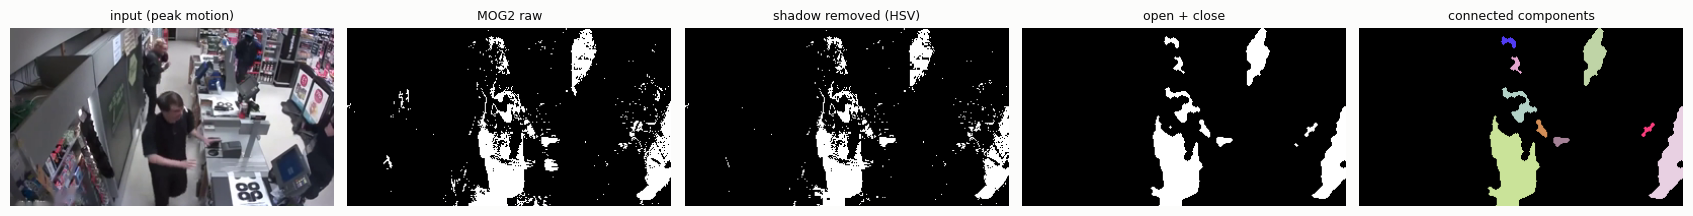

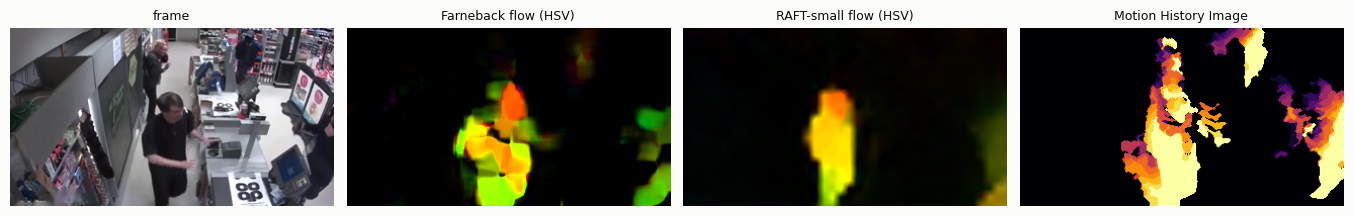

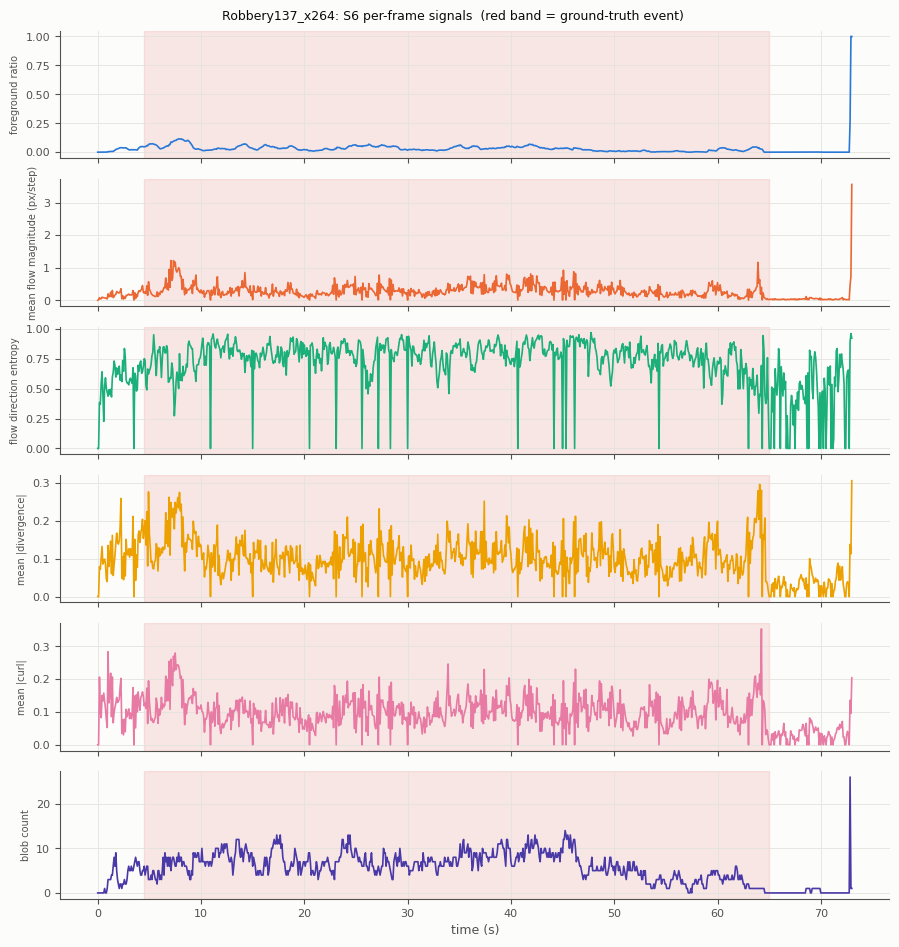

In [6]:
mo = motion.analyze_motion(frames_e, cfg)
bad = clean.bad_frame_mask(cl, len(frames_e))
sc = motion.pick_showcase(mo, bad, prefer=(gt_sec[0][0] * 12, gt_sec[0][1] * 12) if gt_sec else None)
a, b = max(0, sc - 80), min(len(frames_e), sc + 9)
sh = motion.analyze_motion(frames_e[a:b], cfg, showcase=sc - a)['show']
k = len(sh['frames']) // 2
m3 = lambda x: cv2.cvtColor(x, cv2.COLOR_GRAY2BGR)
show([sh['frames'][k], m3(sh['raw_mask'][k]), m3(sh['noshadow'][k]), m3(sh['morph'][k]), sh['comps'][k]],
     ['input (peak motion)', 'MOG2 raw', 'shadow removed (HSV)', 'open + close', 'connected components'], w=3.4, h=2.8)
rf = motion.raft_vs_farneback(frames_e, [sc], cfg, 'cuda')
show([sh['frames'][k], sh['flow_hsv'][min(k, len(sh['flow_hsv']) - 1)], motion.flow_to_hsv(rf['example'][1]), sh['mhi'][k]],
     ['frame', 'Farneback flow (HSV)', 'RAFT-small flow (HSV)', 'Motion History Image'], w=3.4, h=2.8)
motion._signal_plot(mo, gt=gt_sec, title=STEM + ': S6 per-frame signals'); plt.show()

## S7 — actor analysis
Existing YOLOv11s weights (COCO `yolo11s.pt` chosen over the fine-tuned model — see `DECISIONS.md`), ByteTrack IDs, interaction signals and the smoothed actor-centred 224×224 crop.

detector: coco


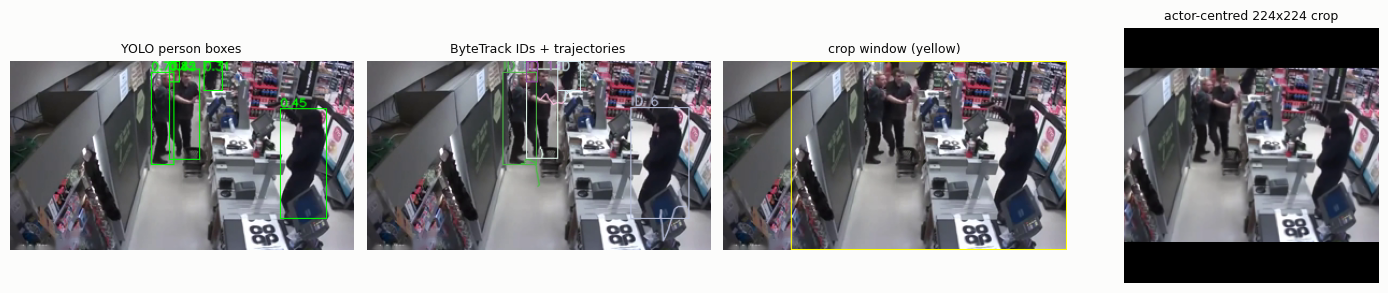

tracks: 37 | crop jitter 2.6px -> 1.2px after smoothing


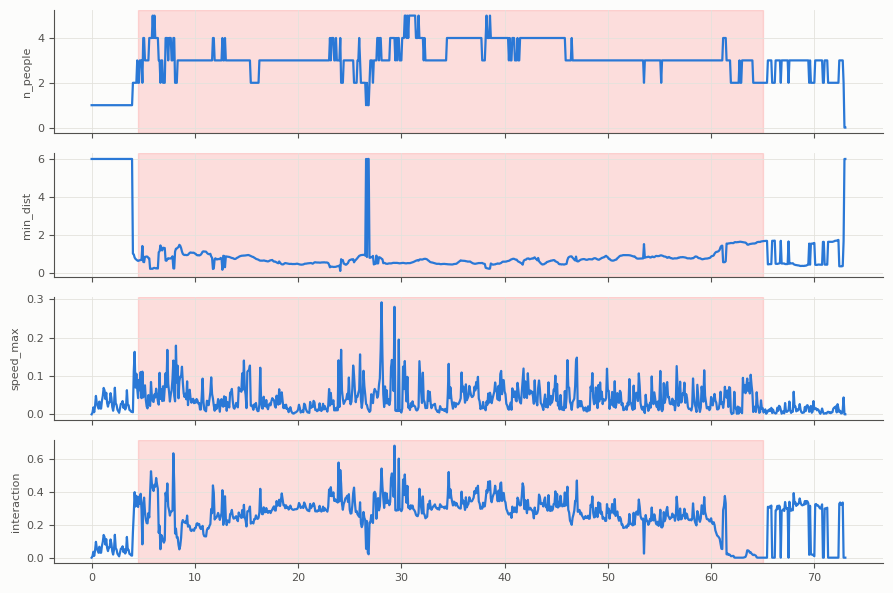

In [7]:
det = actors.get_detector(models)
print('detector:', det.kind)
dets = det.detect(frames_e, conf=cfg['actors']['tracker']['track_low_thresh'])
tracks = actors.track_video(dets, cfg)
sig = actors.interaction_signals(tracks, cfg)
crops = actors.actor_crop_boxes(tracks, frames_e[0].shape[:2], cfg)
t0 = actors.pick_actor_showcase(sig, prefer=(gt_sec[0][0] * 12, gt_sec[0][1] * 12) if gt_sec else None)
vis = [d[d[:, 4] >= cfg['actors']['conf']] for d in dets]
x0, y0, x1, y1 = crops['boxes'][t0]
marked = frames_e[t0].copy(); cv2.rectangle(marked, (x0, y0), (x1 - 1, y1 - 1), (0, 255, 255), 1)
show([actors.draw_boxes(frames_e[t0], vis[t0]), actors.draw_tracks(frames_e[t0], tracks, t0), marked, actors.render_crop(frames_e[t0], crops['boxes'][t0], 224)],
     ['YOLO person boxes', 'ByteTrack IDs + trajectories', 'crop window (yellow)', 'actor-centred 224x224 crop'], w=3.6, h=3)
print(f"tracks: {len({int(r[4]) for tr in tracks for r in tr})} | crop jitter {crops['jitter_raw']:.1f}px -> {crops['jitter_smooth']:.1f}px after smoothing")
fig, axs = plt.subplots(4, 1, figsize=(9, 6), sharex=True)
for ax, key in zip(axs, ['n_people', 'min_dist', 'speed_max', 'interaction']):
    ax.plot(t, np.minimum(sig[key], 6) if key == 'min_dist' else sig[key]); ax.set_ylabel(key, fontsize=8)
    for s_, e_ in gt_sec: ax.axvspan(s_, e_, color='red', alpha=.12)
plt.tight_layout(); plt.show()

## S8 — temporal analytics and clip selection
Activity score (motion + foreground + interaction, Savitzky–Golay smoothed) → hysteresis/peak proposals → clips sampled inside the proposals → quality gate → deduplication.

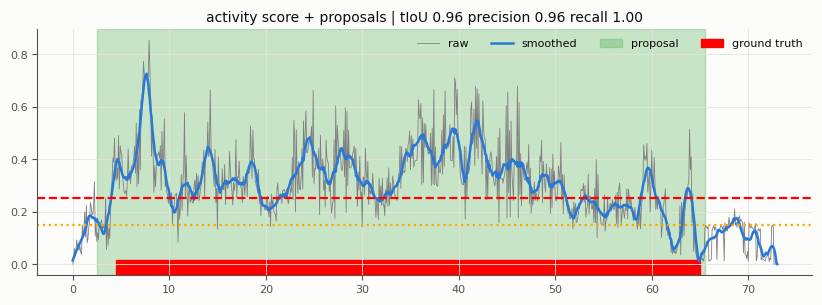

segments (s): [(2.5, 65.5)]


candidates 24 -> gate 24 -> dedup 24 -> kept 16 | rejects {'frozen': 0, 'black': 0, 'blurry': 0, 'low_motion': 0, 'shot_cut': 0, 'illumination_change': 0}
OLD uniform clips: std>0.01 passes 16 / 16 | NEW gate passes 15


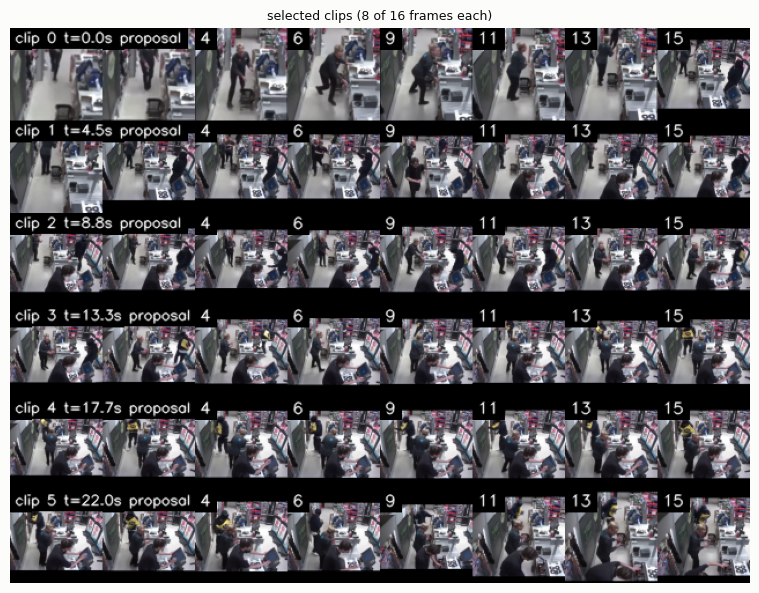

In [8]:
luma_after = en['luma_after']
s8 = temporal.run_s8(frames_e, video['label'], 'train', mo, sig, cl, crops, luma_after, gt_sec, cfg, rng=np.random.RandomState(42))
act = s8['act']
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t, act['raw'], color='gray', lw=.6, label='raw'); ax.plot(t, act['smooth'], lw=1.8, label='smoothed')
ax.axhline(cfg['temporal']['hysteresis']['high'], ls='--', color='red'); ax.axhline(cfg['temporal']['hysteresis']['low'], ls=':', color='orange')
for i, (a_, b_) in enumerate(s8['segments']): ax.axvspan(a_ / 12, b_ / 12, color='tab:green', alpha=.25, label='proposal' if i == 0 else None)
for i, (a_, b_) in enumerate(gt_sec): ax.axvspan(a_, b_, ymax=.06, color='red', label='ground truth' if i == 0 else None)
ge = s8['gt_eval']; ax.set_title(f"activity score + proposals | tIoU {ge['tiou']:.2f} precision {ge['precision']:.2f} recall {ge['recall']:.2f}"); ax.legend(ncol=4, fontsize=8); plt.show()
print('segments (s):', [(round(a_ / 12, 1), round(b_ / 12, 1)) for a_, b_ in s8['segments']])
leg = temporal.legacy_candidates(frames_e, crops['boxes'], video['label'], 'train', cl, mo, luma_after, cfg, np.random.RandomState(42))
print('candidates', s8['n_candidates'], '-> gate', s8['n_passed'], '-> dedup', s8['n_after_dedup'], '-> kept', len(s8['clips']), '| rejects', s8['reject_counts'])
print('OLD uniform clips: std>0.01 passes', sum(c['old_valid'] for c in leg['cands']), '/', len(leg['cands']), '| NEW gate passes', sum(not c['reasons'] for c in leg['cands']))
strips = [temporal._clip_strip(c, 8, 80, f"clip {i} t={x['start']/12:.1f}s {x['kind']}") for i, (c, x) in enumerate(zip(s8['clips'][:6], s8['selected'][:6]))]
show([np.vstack(strips)], ['selected clips (8 of 16 frames each)'], w=9, h=6)

## S9 — packaging
uint8 `(16,224,224,3)` clips + a JSON sidecar per clip (written to a scratch folder, not the training folders).

Robbery137_x264_c0008.npy uint8 (16, 224, 224, 3) 2.41 MB (float32 legacy would be 9.63 MB)


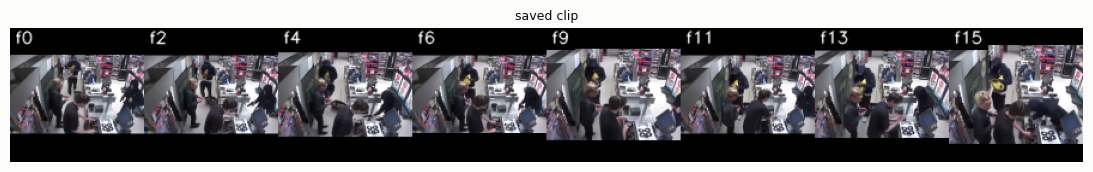

{
 "pipeline": "vpa-1.0",
 "video": "Robbery137_x264",
 "label": "Robbery",
 "split": "train",
 "fold": 1,
 "clip_index": 8,
 "start_frame_12fps": 422,
 "end_frame_12fps": 482,
 "start_time_s": 35.167,
 "end_time_s": 40.25,
 "shot_id": 0,
 "n_shots_in_video": 2,
 "selection_kind": "proposal",
 "window_activity": 0.4506,
 "stats": {
  "motion_energy_mean": 0.4424,
  "motion_energy_max": 0.8036,
  "flow_entropy_mean": 0.8019,
  "flow_div_mean": 0.1192,
  "flow_curl_mean": 0.1176,
  "fg_ratio_mean": 0.0392,
  "blob_count_mean": 8.8197,
  "people_count_mean": 3.9672,
  "people_count_max": 5,
  "min_person_distance_mean": 0.4942,
  "max_iou_mean": 0.1865,
  "speed_max_mean": 0.0499,
  "interaction_mean": 0.3583,
  "brightness_before": 99.0844,
  "brightness_after": 99.0844,
  "enhanced_fraction": 0.0,
  "activity_mean": 0.4506
 },
 "framing": "actor",
 "video_content_box_xyxy": [
  0,
  32,
  320,
  208
 ],
 "overlay_removed": true,
 "quality_gate": {
  "passed": true,
  "reasons": []
 },
 

,clips,videos
Robbery,16,1


In [9]:
out_root = ROOT / 'outputs' / 'vpa_notebook_clips'
res_like = dict(stem=STEM, label=video['label'], split='train', dec=dec, s8=s8, clean=cl, crops=crops, motion=mo, interaction=sig, enhance=en)
pk = package.save_video_clips(res_like, out_root, 1, cfg)
f = pk['files'][len(pk['files']) // 2]
clip = np.load(f)
print(f.name, clip.dtype, clip.shape, f'{clip.nbytes/1e6:.2f} MB (float32 legacy would be {clip.size*4/1e6:.2f} MB)')
show([viz.filmstrip([cv2.cvtColor(x, cv2.COLOR_RGB2BGR) for x in clip], 8, 112, labels=[f'f{i}' for i in range(16)])], ['saved clip'], w=11, h=2)
side = json.loads(Path(f).with_suffix('.json').read_text())
print(json.dumps({k: v for k, v in side.items() if k not in ('frame_indices_12fps', 'source_frame_indices', 'source_times_s', 'crop_boxes_xyxy')}, indent=1)[:1800])
rep = package.build_report(pk['rows'], [pk['vrow']], None, save_samples=False)
display(pd.DataFrame(rep['per_class']).T[['clips', 'videos']])

## Summary

All numbers above come from one video; `docs/vpa_samples/INDEX.md` links the saved input/output sample of **every operation for every one of the 8 sample videos**.
Training and the VideoMAE ablations are *not* part of this notebook — the pipeline above only prepares the data.